# Example 1.2 — Degrees of Freedom: Grübler Formula
**Four Bar Mechanisms: Synthesis with Genetic Algorithms and Neural Networks**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/)

---
## Statement
Apply the Grübler formula to calculate the degrees of freedom (DOF) of:
1. A four-bar mechanism with four kinematic pairs of revolution.
2. An open kinematic chain with the same number of links.
3. A slider-crank mechanism.

## Theoretical foundation
The **Grübler formula** for planar mechanisms is:

$$F = 3(n - 1) - 2j_1 - j_2$$

where:
- $n$ = total number of links (including frame)
- $j_1$ = number of joints of order 1 (revolute, prismatic)
- $j_2$ = number of joints of order 2
- $F$ = degrees of freedom (DOF)

| Mechanism type | $n$ | $j_1$ | $j_2$ | $F$ |
|---|---|---|---|---|
| Closed four-bar | 4 | 4 | 0 | 1 |
| 4-link open chain | 4 | 3 | 0 | 3 |
| Slider-crank | 4 | 4 | 0 | 1 |

In [ ]:
from numpy import *

def grubler(n_links, j1, j2=0):
    """Grübler's formula for planar mechanisms.
    n_links: total number of links (including the frame)
    j1: joints of order 1 (revolute, prismatic)
    j2: joints of order 2
    """
    F = 3 * (n_links - 1) - 2 * j1 - j2
    return int(F)

# Closed four-bar mechanism
n, j1 = 4, 4
dof = grubler(n, j1)
print(f"Closed four-bar:             n={n}, j1={j1} → DOF = {dof}")

# 4-Link Open Chain (3-DOF Planar Robot)
n_oc, j1_oc = 4, 3
dof_oc = grubler(n_oc, j1_oc)
print(f"4-link open chain:           n={n_oc}, j1={j1_oc} → DOF = {dof_oc}")

# Slider-crank
n_sc, j1_sc = 4, 4   # a prismatic pair counts as j1
dof_sc = grubler(n_sc, j1_sc)
print(f"Slider-crank:                n={n_sc}, j1={j1_sc} → DOF = {dof_sc}")

Closed four-bar:             n=4, j1=4 → DOF = 1
4-link open chain:           n=4, j1=3 → DOF = 3
Slider-crank:                n=4, j1=4 → DOF = 1


## Display
The following block generates schematic diagrams of each kinematic chain with its DOF.

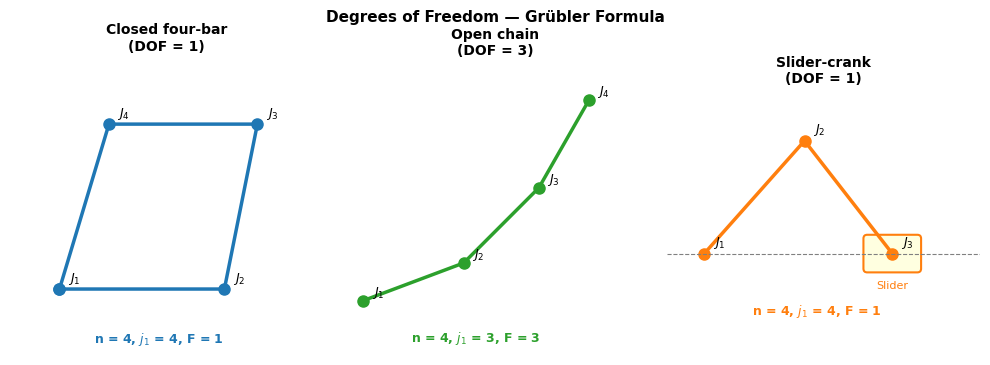

Figure saved as figura_1_2_grubler_degrees_of_freedom.pdf and figura_1_2_grubler_degrees_of_freedom.png


In [1]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# 1. Configuración de Nombre de Archivo Automatizado (Requisitos de Springer)
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "figura_1_2_grubler_degrees_of_freedom"
except Exception:
    notebook_name = "figura_1_2_grubler_degrees_of_freedom"

# Configuración de tipos de fuente vectorial
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'

# 2. Configuración física de figura (compacta pero legible de 3 paneles)
fig, axes = plt.subplots(1, 3, figsize=(10, 3.8))
titles = [
    'Closed four-bar\n(DOF = 1)',
    'Open chain\n(DOF = 3)',
    'Slider-crank\n(DOF = 1)'
]

# --- Panel 1: Closed four-bar ---
ax = axes[0]
pts = np.array([[0,0],[1,0],[1.2,1],[0.3,1],[0,0]])
ax.plot(pts[:,0], pts[:,1], 'o-', color='C0', lw=2.5, ms=8)
for i,(x,y) in enumerate(pts[:4]):
    ax.annotate(f'$J_{i+1}$', (x,y), textcoords='offset points', xytext=(6,6), fontsize=9)
ax.set_title(titles[0], fontsize=10, fontweight='bold')

# Ajuste de límites para evitar traslapes de textos inferiores
ax.set_xlim(-0.3, 1.6)
ax.set_ylim(-0.4, 1.4)
ax.set_aspect('equal')
ax.axis('off')
ax.text(0.6, -0.32, 'n = 4, $j_1$ = 4, F = 1', ha='center', fontsize=9, color='C0', fontweight='bold')

# --- Panel 2: Open chain ---
ax = axes[1]
pts2 = np.array([[0,0],[0.8,0.3],[1.4,0.9],[1.8,1.6]])
ax.plot(pts2[:,0], pts2[:,1], 'o-', color='C2', lw=2.5, ms=8)
for i,(x,y) in enumerate(pts2):
    ax.annotate(f'$J_{i+1}$', (x,y), textcoords='offset points', xytext=(6,4), fontsize=9)
ax.set_title(titles[1], fontsize=10, fontweight='bold')

# Ajuste de límites para evitar traslapes de textos inferiores
ax.set_xlim(-0.2, 2.3)
ax.set_ylim(-0.4, 1.9)
ax.set_aspect('equal')
ax.axis('off')
ax.text(0.9, -0.32, 'n = 4, $j_1$ = 3, F = 3', ha='center', fontsize=9, color='C2', fontweight='bold')

# --- Panel 3: Crank-slider ---
ax = axes[2]
ax.plot([0,0.8,1.5],[0,0.9,0], 'o-', color='C1', lw=2.5, ms=8)

# Caja para el slider
rect = mpatches.FancyBboxPatch((1.3,-0.12), 0.4, 0.24, boxstyle='round,pad=0.03',
                               fc='lightyellow', ec='C1', lw=1.5)
ax.add_patch(rect)
ax.annotate('Slider', (1.5,-0.12), textcoords='offset points', xytext=(0,-14),
            ha='center', fontsize=8, color='C1')
ax.axhline(0, color='gray', lw=0.8, ls='--')

for i,(x,y) in enumerate([(0,0),(0.8,0.9),(1.5,0)]):
    ax.annotate(f'$J_{i+1}$', (x,y), textcoords='offset points', xytext=(6,6), fontsize=9)
ax.set_title(titles[2], fontsize=10, fontweight='bold')

# Ajuste de límites para evitar traslapes de textos inferiores
ax.set_xlim(-0.3, 2.2)
ax.set_ylim(-0.55, 1.3)
ax.set_aspect('equal')
ax.axis('off')
ax.text(0.9, -0.48, 'n = 4, $j_1$ = 4, F = 1', ha='center', fontsize=9, color='C1', fontweight='bold')

# Título General y Guardado
plt.suptitle('Degrees of Freedom — Grübler Formula', fontsize=11, fontweight='bold')
plt.tight_layout()

# Exportación y Guardado según directrices de Springer
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')

plt.show()
print(f"Figure saved as {notebook_name}.pdf and {notebook_name}.png")